# K-Means Clustering — World Happiness Report
**23CSE301 Machine Learning · Capstone (Clustering track, Review 2)**

**Goal:** group countries with similar well-being profiles using K-Means, **without** using any label.
Dataset: *World Happiness Report* (country-year panel, 2005–2022), aggregated to one row per country.
`Regional Indicator` is held out and used only *after* clustering to sanity-check the result.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, warnings
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid", palette="colorblind")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12})

## 1. Dataset loading & inspection

In [2]:
raw = pd.read_csv("../data/world_happiness_report.csv")
print("Shape:", raw.shape)
print("Countries:", raw["Country Name"].nunique(), "| Years:", raw["Year"].min(), "-", raw["Year"].max())
print("Duplicate rows:", raw.duplicated().sum())
display(raw.dtypes.astype(str).to_frame("dtype").join(raw.isna().sum().rename("missing")))
raw.head()

Shape: (2199, 13)
Countries: 165 | Years: 2005 - 2022
Duplicate rows: 0


,dtype,missing
Country Name,str,0
Regional Indicator,str,112
Year,int64,0
Life Ladder,float64,0
Log GDP Per Capita,float64,20
Social Support,float64,13
Healthy Life Expectancy At Birth,float64,54
Freedom To Make Life Choices,float64,33
Generosity,float64,73
Perceptions Of Corruption,float64,116


,Country Name,Regional Indicator,Year,Life Ladder,Log GDP Per Capita,Social Support,Healthy Life Expectancy At Birth,Freedom To Make Life Choices,Generosity,Perceptions Of Corruption,Positive Affect,Negative Affect,Confidence In National Government
0,Afghanistan,South Asia,2008,3.723590,7.350416,0.450662,50.500000,0.718114,0.167652,0.881686,0.414297,0.258195,0.612072
1,Afghanistan,South Asia,2009,4.401778,7.508646,0.552308,50.799999,0.678896,0.190809,0.850035,0.481421,0.237092,0.611545
2,Afghanistan,South Asia,2010,4.758381,7.613900,0.539075,51.099998,0.600127,0.121316,0.706766,0.516907,0.275324,0.299357
3,Afghanistan,South Asia,2011,3.831719,7.581259,0.521104,51.400002,0.495901,0.163571,0.731109,0.479835,0.267175,0.307386
4,Afghanistan,South Asia,2012,3.782938,7.660506,0.520637,51.700001,0.530935,0.237588,0.775620,0.613513,0.267919,0.435440


**Observation:** the file is a panel (several rows per country). Most indicators have some missing values, and *Confidence In National Government* has the most. There are no duplicate rows.

## 2. Cleaning, feature selection, encoding & scaling
Countries are the natural unit to cluster, so the panel is averaged per country. Each decision is commented in the code.

Country-level table: (165, 10)
Missing cells before imputation: 31
IQR outlier counts per feature:
Life Ladder                           0
Log GDP Per Capita                    0
Social Support                        5
Healthy Life Expectancy At Birth      2
Freedom To Make Life Choices          1
Generosity                            4
Perceptions Of Corruption            18
Positive Affect                       0
Negative Affect                       4
Confidence In National Government     2
Dropped for redundancy (|r|>0.90): none


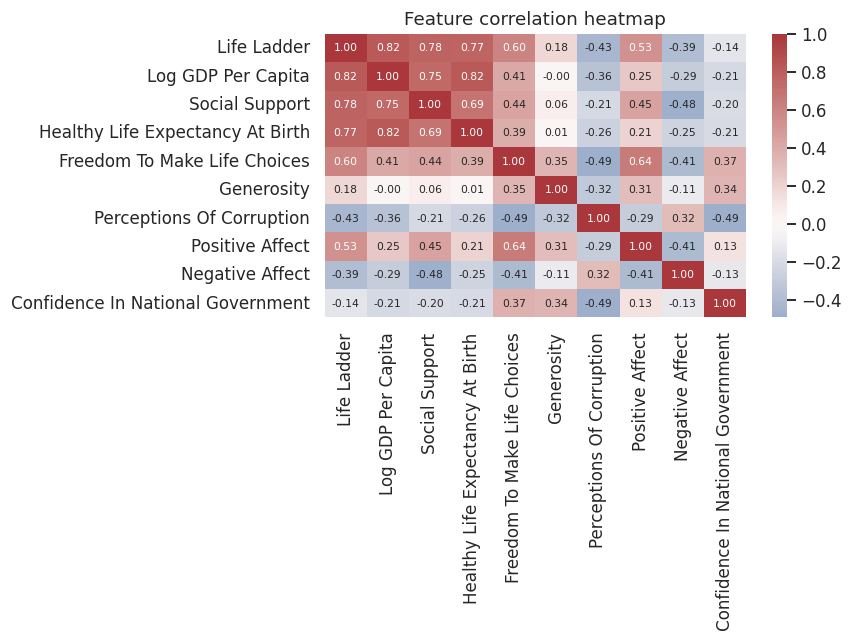

Model input: (165, 10) | mean~0: True | std~1: True


In [3]:
# --- Cleaning ---------------------------------------------------------------
# Regional Indicator is missing for some rows: recover it from the same country's other years.
# It is used ONLY for post-hoc validation, never as a clustering input.
region = raw.groupby("Country Name")["Regional Indicator"].agg(lambda s: s.mode().iloc[0] if s.notna().any() else "Unknown")
FEATURES = [c for c in raw.columns if c not in ["Country Name", "Regional Indicator", "Year"]]
# Aggregate the panel to one row per country (mean over available years; NaNs are skipped).
df = raw.groupby("Country Name")[FEATURES].mean()
print("Country-level table:", df.shape)
print("Missing cells before imputation:", int(df.isna().sum().sum()))
df = df.fillna(df.median())          # median imputation: robust to skew/outliers
true_region = region.loc[df.index]   # kept aside for validation only
# --- Outliers (IQR rule): reported, kept (they are real countries, not errors) ---
q1, q3 = df.quantile(.25), df.quantile(.75); iqr = q3 - q1
print("IQR outlier counts per feature:"); print(((df < q1 - 1.5*iqr) | (df > q3 + 1.5*iqr)).sum().to_string())
# --- Feature selection: drop one of any pair with |r| > 0.90 ----------------
corr = df.corr(); upper = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool))
drop = [c for c in upper.columns if (upper[c].abs() > 0.90).any()]
print("Dropped for redundancy (|r|>0.90):", drop or "none")
plt.figure(figsize=(8, 6)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, annot_kws={"size": 7})
plt.title("Feature correlation heatmap"); plt.tight_layout(); plt.show()
df = df.drop(columns=drop); FEATURES = list(df.columns)
# --- Encoding: all selected features are numeric, so no encoding is needed ---
assert all(pd.api.types.is_numeric_dtype(t) for t in df.dtypes)
# --- Scaling: distance-based methods need comparable scales ------------------
# (Unsupervised task -> no train/test split; the scaler is fitted on the full country table.)
X = StandardScaler().fit_transform(df)
print("Model input:", X.shape, "| mean~0:", np.allclose(X.mean(0), 0), "| std~1:", np.allclose(X.std(0), 1))

## 3. K-Means for multiple k
For each k=2…10 we record inertia (within-cluster SSE) and three internal validity metrics.

In [4]:
def quality(X, labels):
    return dict(silhouette=silhouette_score(X, labels), davies_bouldin=davies_bouldin_score(X, labels),
                calinski_harabasz=calinski_harabasz_score(X, labels))

from sklearn.cluster import KMeans
rows = []
for k in range(2, 11):
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    rows.append(dict(k=k, inertia=km.inertia_, **quality(X, km.labels_)))
sweep = pd.DataFrame(rows).set_index("k")
sweep.round(3)

,inertia,silhouette,davies_bouldin,calinski_harabasz
k,,,,
2,1149.118,0.265,1.446,71.049
3,931.196,0.242,1.400,62.525
4,804.372,0.230,1.393,56.419
5,715.100,0.225,1.395,52.295
6,659.425,0.229,1.402,47.769
7,614.887,0.205,1.434,44.330
8,579.302,0.210,1.437,41.454
9,558.039,0.189,1.451,38.157
10,532.208,0.182,1.514,36.172


## 4. Elbow curve & silhouette comparison

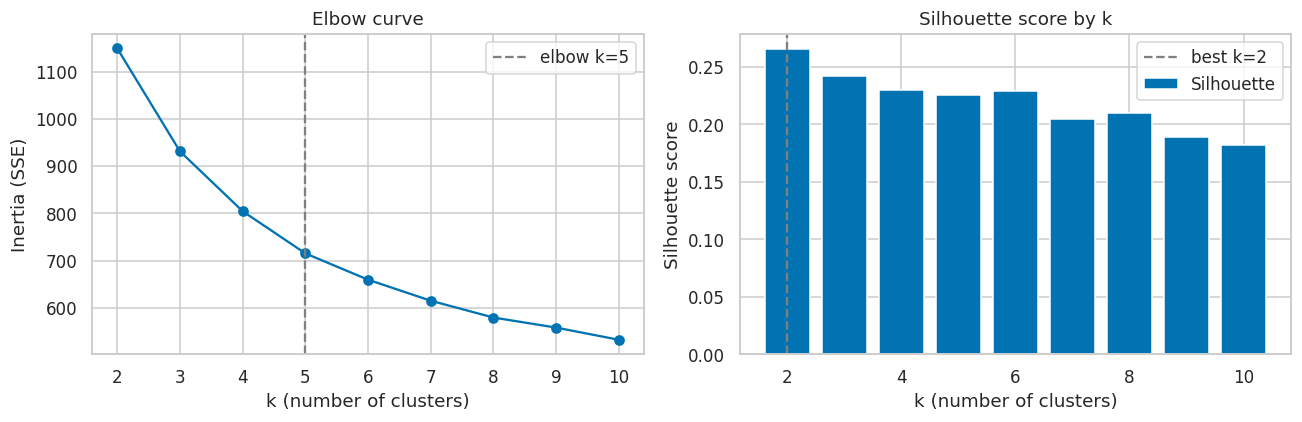

Elbow suggests k=5; highest silhouette at k=2.


In [5]:
ks = sweep.index.to_numpy(); y = sweep["inertia"].to_numpy()
# "Elbow" = point farthest from the straight line joining the first and last inertia values
p1, p2 = np.array([ks[0], y[0]], float), np.array([ks[-1], y[-1]], float)
dv = p2 - p1
d = [abs(dv[0]*(p1[1]-v) - dv[1]*(p1[0]-k)) / np.linalg.norm(dv) for k, v in zip(ks, y)]
k_elbow = int(ks[int(np.argmax(d))]); k_sil = int(sweep["silhouette"].idxmax())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, y, "o-"); ax[0].axvline(k_elbow, ls="--", c="gray", label=f"elbow k={k_elbow}")
ax[0].set(title="Elbow curve", xlabel="k (number of clusters)", ylabel="Inertia (SSE)"); ax[0].legend()
ax[1].bar(ks, sweep["silhouette"], color=sns.color_palette("colorblind")[0], label="Silhouette")
ax[1].set(title="Silhouette score by k", xlabel="k (number of clusters)", ylabel="Silhouette score")
ax[1].axvline(k_sil, ls="--", c="gray", label=f"best k={k_sil}"); ax[1].legend()
plt.tight_layout(); plt.show()
print(f"Elbow suggests k={k_elbow}; highest silhouette at k={k_sil}.")

**How we choose k:** the elbow is a geometric heuristic and can be ambiguous; the silhouette score gives a quantitative comparison. We use the **silhouette-optimal k** as the final choice and report the elbow k alongside it, so any disagreement is visible rather than hidden.

Chosen k = 2


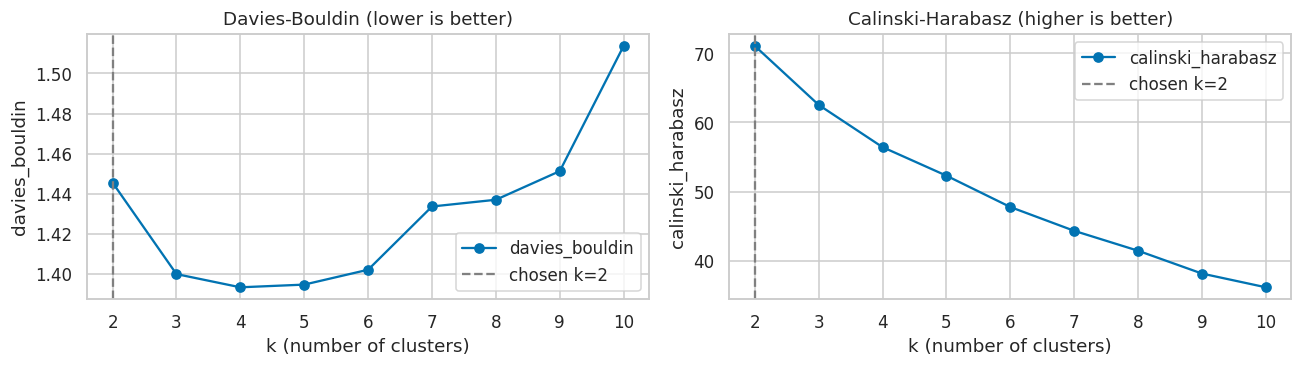

In [6]:
K_FINAL = k_sil
print("Chosen k =", K_FINAL)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for a, col, t in zip(ax, ["davies_bouldin", "calinski_harabasz"], ["Davies-Bouldin (lower is better)", "Calinski-Harabasz (higher is better)"]):
    a.plot(ks, sweep[col], "o-", label=col); a.axvline(K_FINAL, ls="--", c="gray", label=f"chosen k={K_FINAL}")
    a.set(title=t, xlabel="k (number of clusters)", ylabel=col); a.legend()
plt.tight_layout(); plt.show()

## 5. Final model: cluster assignments, sizes & profiles

Final metrics: {'silhouette': 0.265, 'davies_bouldin': 1.446, 'calinski_harabasz': 71.049}


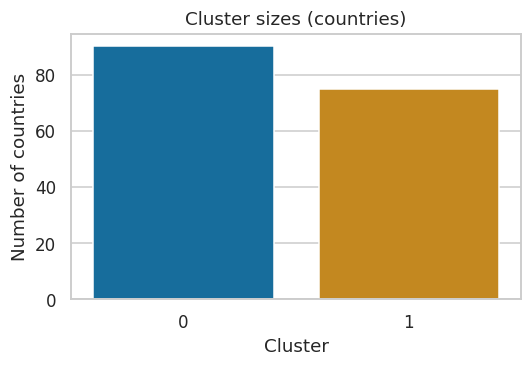

,n_countries,Life Ladder,Log GDP Per Capita,Social Support,Healthy Life Expectancy At Birth,Freedom To Make Life Choices,Generosity,Perceptions Of Corruption,Positive Affect,Negative Affect,Confidence In National Government
cluster,,,,,,,,,,,
0,90,6.17,10.08,0.88,66.96,0.81,0.02,0.70,0.7,0.25,0.48
1,75,4.49,8.40,0.71,57.22,0.66,-0.01,0.78,0.6,0.31,0.54


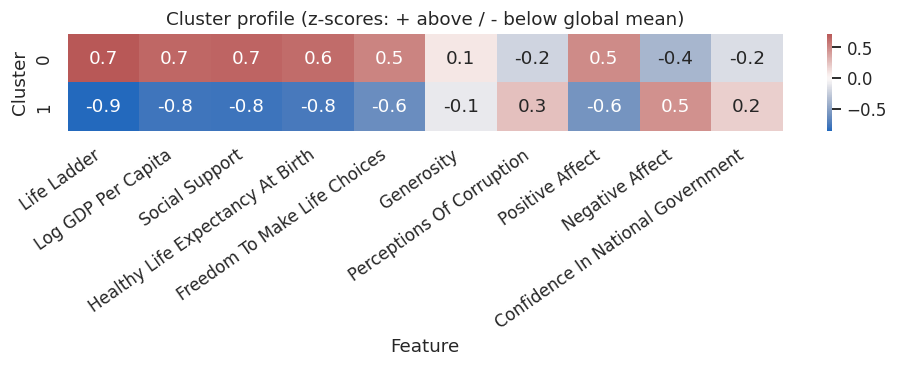

Cluster 0: Argentina, Australia, Austria, Bahrain, Belarus, Belgium, Belize, Bhutan ...
Cluster 1: Afghanistan, Albania, Algeria, Angola, Armenia, Azerbaijan, Bangladesh, Benin ...


In [7]:
km = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE).fit(X)
result = df.copy(); result["cluster"] = km.labels_
sizes = result["cluster"].value_counts().sort_index()
print("Final metrics:", {k: round(v, 3) for k, v in quality(X, km.labels_).items()})
plt.figure(figsize=(5, 3.5)); sns.barplot(x=sizes.index, y=sizes.values, hue=sizes.index, palette="colorblind", legend=False)
plt.title("Cluster sizes (countries)"); plt.xlabel("Cluster"); plt.ylabel("Number of countries"); plt.tight_layout(); plt.show()
profile = result.groupby("cluster").mean().round(2); profile.insert(0, "n_countries", sizes)
display(profile)
z = pd.DataFrame(StandardScaler().fit_transform(df), index=df.index, columns=df.columns).groupby(km.labels_).mean()
plt.figure(figsize=(9, 3.5)); sns.heatmap(z, annot=True, fmt=".1f", cmap="vlag", center=0)
plt.title("Cluster profile (z-scores: + above / - below global mean)"); plt.xlabel("Feature"); plt.ylabel("Cluster")
plt.xticks(rotation=35, ha="right"); plt.tight_layout(); plt.show()
for cl in range(K_FINAL):
    print(f"Cluster {cl}:", ", ".join(result.index[result.cluster == cl][:8]), "...")

## 6. Cluster visualisation (PCA, plus t-SNE)

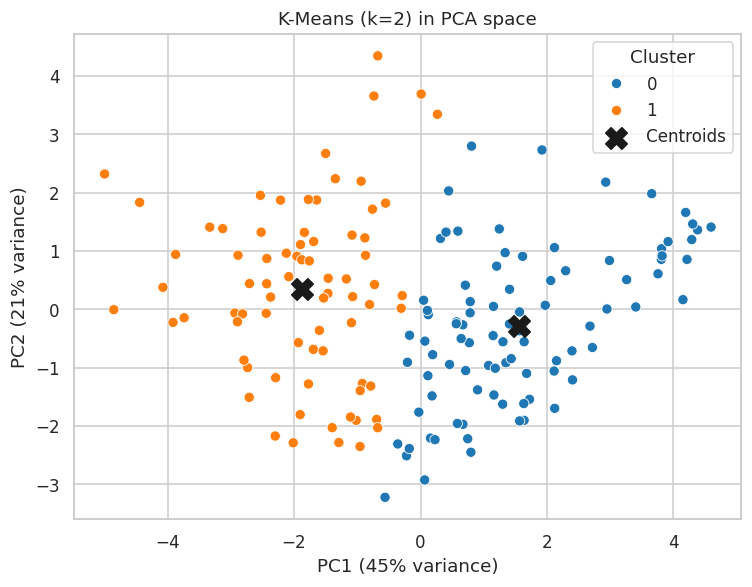

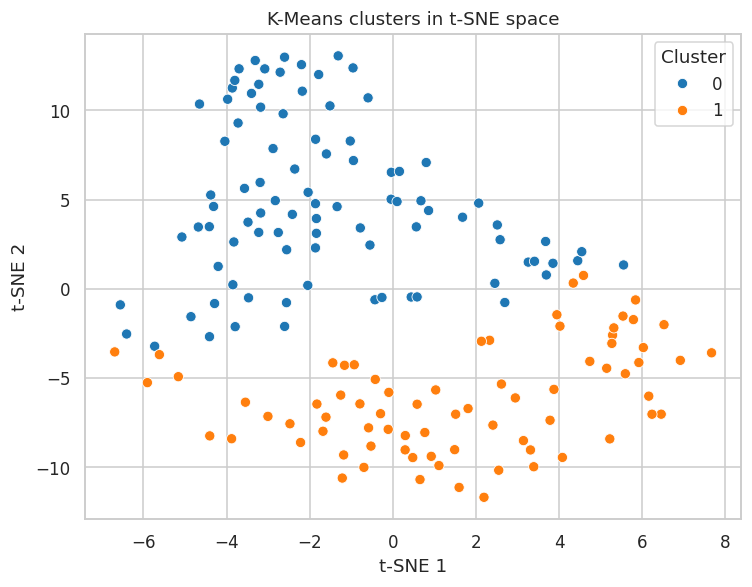

In [8]:
pca = PCA(n_components=2, random_state=RANDOM_STATE); P = pca.fit_transform(X); C_ = pca.transform(km.cluster_centers_)
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.scatterplot(x=P[:, 0], y=P[:, 1], hue=km.labels_, palette="tab10", s=45, ax=ax, legend="full")
ax.scatter(C_[:, 0], C_[:, 1], c="k", marker="X", s=200, label="Centroids")
ax.set(title=f"K-Means (k={K_FINAL}) in PCA space", xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} variance)", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} variance)")
ax.legend(title="Cluster"); plt.tight_layout(); plt.show()
T = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(X)
plt.figure(figsize=(7, 5.5)); sns.scatterplot(x=T[:, 0], y=T[:, 1], hue=km.labels_, palette="tab10", s=45)
plt.title("K-Means clusters in t-SNE space"); plt.xlabel("t-SNE 1"); plt.ylabel("t-SNE 2"); plt.legend(title="Cluster"); plt.tight_layout(); plt.show()

## 7. Post-hoc validation with the held-out labels
`Regional Indicator` was **not** used for fitting. We only check how clusters relate to geography afterwards.

In [9]:
mask = (true_region != "Unknown").to_numpy()
print("Adjusted Rand Index vs Regional Indicator:", round(adjusted_rand_score(true_region[mask], km.labels_[mask]), 3), "(0 = random, 1 = identical)")
display(pd.crosstab(true_region[mask].rename("Region"), pd.Series(km.labels_[mask], index=true_region[mask].index, name="Cluster")))

Adjusted Rand Index vs Regional Indicator: 0.17 (0 = random, 1 = identical)


Cluster,0,1
Region,,
Central and Eastern Europe,11,5
Commonwealth of Independent States,6,6
East Asia,6,0
Latin America and Caribbean,19,1
Middle East and North Africa,6,9
North America and ANZ,4,0
South Asia,2,5
Southeast Asia,6,3
Sub-Saharan Africa,1,34


## 8. Conclusion

In [10]:
best_row = sweep.loc[K_FINAL]
print(f"""Summary (all numbers computed above):
- Data: {X.shape[0]} countries x {X.shape[1]} indicators after cleaning and standardisation.
- k scanned 2-10. Elbow k={k_elbow}; silhouette-optimal k={k_sil} (silhouette={best_row.silhouette:.3f}).
- Final model k={K_FINAL}: Davies-Bouldin={best_row.davies_bouldin:.3f}, Calinski-Harabasz={best_row.calinski_harabasz:.1f}.
- Cluster sizes: {sizes.to_dict()}.
- PCA first two components explain {pca.explained_variance_ratio_.sum():.0%} of the variance.""")

Summary (all numbers computed above):
- Data: 165 countries x 10 indicators after cleaning and standardisation.
- k scanned 2-10. Elbow k=5; silhouette-optimal k=2 (silhouette=0.265).
- Final model k=2: Davies-Bouldin=1.446, Calinski-Harabasz=71.0.
- Cluster sizes: {0: 90, 1: 75}.
- PCA first two components explain 65% of the variance.


**Interpretation notes.** Read the z-score heatmap in §5 to name each cluster (e.g. which cluster is high in GDP, life expectancy and social support). A silhouette well below 0.5 means the groups form a *continuum* rather than sharply separated blobs, which is common for socio-economic data, so the clusters are best treated as useful segments rather than natural categories.

**Limitations:** K-Means assumes roughly spherical, equal-variance clusters; results use country means over 2005–2022 and hide trends over time; median imputation is a simplification.